# 1)- Data Cleaning and Preprocessing

## 1.1 ) Loading dataset (E-Commerce Data)

In [ ]:
import pandas as pd
import numpy as np

# Load the dataset
df = pd.read_csv('E-Commerce Data.csv', encoding='ISO-8859-1')

df.head()


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,12/1/2010 8:26,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,12/1/2010 8:26,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,12/1/2010 8:26,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,12/1/2010 8:26,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,12/1/2010 8:26,3.39,17850.0,United Kingdom


## 1.2 ) Check for missing values

In [ ]:
df.isnull().sum()


,0
InvoiceNo,0
StockCode,0
Description,1454
Quantity,0
InvoiceDate,0
UnitPrice,0
CustomerID,135080
Country,0


## 1.3 ) Handle missing CustomerID and drop rows with critical missing data

In [ ]:
# Drop rows with missing CustomerID since it's critical for analysis
df = df.dropna(subset=['CustomerID'])

# Check again missing values
df.isnull().sum()


,0
InvoiceNo,0
StockCode,0
Description,0
Quantity,0
InvoiceDate,0
UnitPrice,0
CustomerID,0
Country,0


## 1.4 ) Remove duplicate rows

In [ ]:
df = df.drop_duplicates()


## 1.5 ) Handle outliers in Quantity and UnitPrice

In [ ]:
# Basic outlier handling: remove transactions where Quantity <= 0 or UnitPrice <= 0
df = df[(df['Quantity'] > 0) & (df['UnitPrice'] > 0)]


## 1.6 ) Create TotalRevenue column

In [ ]:
df['TotalRevenue'] = df['Quantity'] * df['UnitPrice']


<ipython-input-29-0021b0355ac9>:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df['TotalRevenue'] = df['Quantity'] * df['UnitPrice']


# 2)- Data Manipulation and Analysis

## 2.1 ) Calculate total revenue by country

In [ ]:
revenue_by_country = df.groupby('Country')['TotalRevenue'].sum().sort_values(ascending=False)
print(revenue_by_country)


Country
United Kingdom          7285024.644
Netherlands              285446.340
EIRE                     265262.460
Germany                  228678.400
France                   208934.310
Australia                138453.810
Spain                     61558.560
Switzerland               56443.950
Belgium                   41196.340
Sweden                    38367.830
Japan                     37416.370
Norway                    36165.440
Portugal                  33375.840
Finland                   22546.080
Singapore                 21279.290
Channel Islands           20440.540
Denmark                   18955.340
Italy                     17483.240
Cyprus                    13502.850
Austria                   10198.680
Poland                     7334.650
Israel                     7215.840
Greece                     4760.520
Iceland                    4310.000
Canada                     3666.380
USA                        3580.390
Malta                      2725.590
Unspecified         

## 2.2 ) Identify top 10 products by total revenue

In [ ]:
top_products = df.groupby('Description')['TotalRevenue'].sum().sort_values(ascending=False).head(10)
print(top_products)


Description
PAPER CRAFT , LITTLE BIRDIE           168469.60
REGENCY CAKESTAND 3 TIER              142264.75
WHITE HANGING HEART T-LIGHT HOLDER    100392.10
JUMBO BAG RED RETROSPOT                85040.54
MEDIUM CERAMIC TOP STORAGE JAR         81416.73
POSTAGE                                77803.96
PARTY BUNTING                          68785.23
ASSORTED COLOUR BIRD ORNAMENT          56413.03
Manual                                 53419.93
RABBIT NIGHT LIGHT                     51251.24
Name: TotalRevenue, dtype: float64


## 2.3 ) Group data by month to analyze monthly sales trends

In [ ]:
df['InvoiceDate'] = pd.to_datetime(df['InvoiceDate'])
df['Month'] = df['InvoiceDate'].dt.to_period('M')

monthly_sales = df.groupby('Month')['TotalRevenue'].sum()
print(monthly_sales)


Month
2010-12     570422.730
2011-01     568101.310
2011-02     446084.920
2011-03     594081.760
2011-04     468374.331
2011-05     677355.150
2011-06     660046.050
2011-07     598962.901
2011-08     644051.040
2011-09     950690.202
2011-10    1035642.450
2011-11    1156205.610
2011-12     517190.440
Freq: M, Name: TotalRevenue, dtype: float64


## 2.4 ) Calculate unique customers per country

In [ ]:
unique_customers = df.groupby('Country')['CustomerID'].nunique()
print(unique_customers)


Country
Australia                  9
Austria                   11
Bahrain                    2
Belgium                   25
Brazil                     1
Canada                     4
Channel Islands            9
Cyprus                     8
Czech Republic             1
Denmark                    9
EIRE                       3
European Community         1
Finland                   12
France                    87
Germany                   94
Greece                     4
Iceland                    1
Israel                     3
Italy                     14
Japan                      8
Lebanon                    1
Lithuania                  1
Malta                      2
Netherlands                9
Norway                    10
Poland                     6
Portugal                  19
RSA                        1
Saudi Arabia               1
Singapore                  1
Spain                     30
Sweden                     8
Switzerland               21
USA                        4
United

## 2.5 ) Identify customers with highest spending

In [ ]:
top_customers = df.groupby('CustomerID')['TotalRevenue'].sum().sort_values(ascending=False).head(10)
print(top_customers)


CustomerID
14646.0    280206.02
18102.0    259657.30
17450.0    194390.79
16446.0    168472.50
14911.0    143711.17
12415.0    124914.53
14156.0    117210.08
17511.0     91062.38
16029.0     80850.84
12346.0     77183.60
Name: TotalRevenue, dtype: float64


## 2.6 ) Determine average order value (AOV) per country

In [ ]:
# Calculate revenue and order counts per country
country_order_data = df.groupby('Country').agg({'TotalRevenue':'sum', 'InvoiceNo':'nunique'})
country_order_data['AOV'] = country_order_data['TotalRevenue'] / country_order_data['InvoiceNo']

print(country_order_data[['AOV']].sort_values(by='AOV', ascending=False))


                              AOV
Country                          
Singapore             3039.898571
Netherlands           3036.663191
Australia             2429.014211
Japan                 1969.282632
Lebanon               1693.880000
Israel                1443.168000
Brazil                1143.600000
Switzerland           1106.744118
Sweden                1065.773056
Denmark               1053.074444
EIRE                  1020.240231
Norway                1004.595556
RSA                   1002.310000
Greece                 952.104000
Cyprus                 843.928125
Channel Islands        786.174615
USA                    716.078000
Spain                  683.984000
United Arab Emirates   634.093333
Iceland                615.714286
Canada                 611.063333
Austria                599.922353
Portugal               585.541053
Finland                549.904390
Malta                  545.118000
France                 537.106195
Germany                500.390372
Italy         

# 3)- Statistical Analysis with NumPy

## 3.1 ) Mean, median, std, variance of total revenues per country

In [ ]:
revenues = revenue_by_country.values

mean_rev = np.mean(revenues)
median_rev = np.median(revenues)
std_rev = np.std(revenues)
var_rev = np.var(revenues)

print(f"Mean: {mean_rev}, Median: {median_rev}, Std Dev: {std_rev}, Variance: {var_rev}")


Mean: 240194.83497297295, Median: 13502.85, Std Dev: 1176577.5132443241, Variance: 1384334644672.198


## 3.2 ) Correlation between Quantity and TotalRevenue

In [ ]:
correlation = np.corrcoef(df['Quantity'], df['TotalRevenue'])[0, 1]
print(f"Correlation between Quantity and TotalRevenue: {correlation}")


Correlation between Quantity and TotalRevenue: 0.9144507831108554


## 3.3 ) Hypothesis Testing: Is average revenue from UK customers higher than others?

In [ ]:
from scipy.stats import ttest_ind

uk_revenue = df[df['Country'] == 'United Kingdom']['TotalRevenue']
other_revenue = df[df['Country'] != 'United Kingdom']['TotalRevenue']

t_stat, p_val = ttest_ind(uk_revenue, other_revenue, equal_var=False)

print(f"T-statistic: {t_stat}, P-value: {p_val}")

if p_val < 0.05:
    print("Reject null hypothesis: UK customers have significantly different average revenue.")
else:
    print("Fail to reject null hypothesis: No significant difference.")


T-statistic: -22.96335389351568, P-value: 1.4503111664518801e-116
Reject null hypothesis: UK customers have significantly different average revenue.


 3.4 ) Linear regression to predict TotalRevenue based on Quantity

In [ ]:
# Simple linear regression using NumPy polyfit
coefficients = np.polyfit(df['Quantity'], df['TotalRevenue'], 1)
slope, intercept = coefficients

print(f"Linear regression equation: TotalRevenue = {slope:.4f} * Quantity + {intercept:.4f}")


Linear regression equation: TotalRevenue = 1.5762 * Quantity + 1.9528


# 4 )- Data Visualization

## 4.1 ) Bar chart showing total revenue by country

<ipython-input-41-66b27bdb6789>:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=revenue_by_country.index, y=revenue_by_country.values, palette='mako')


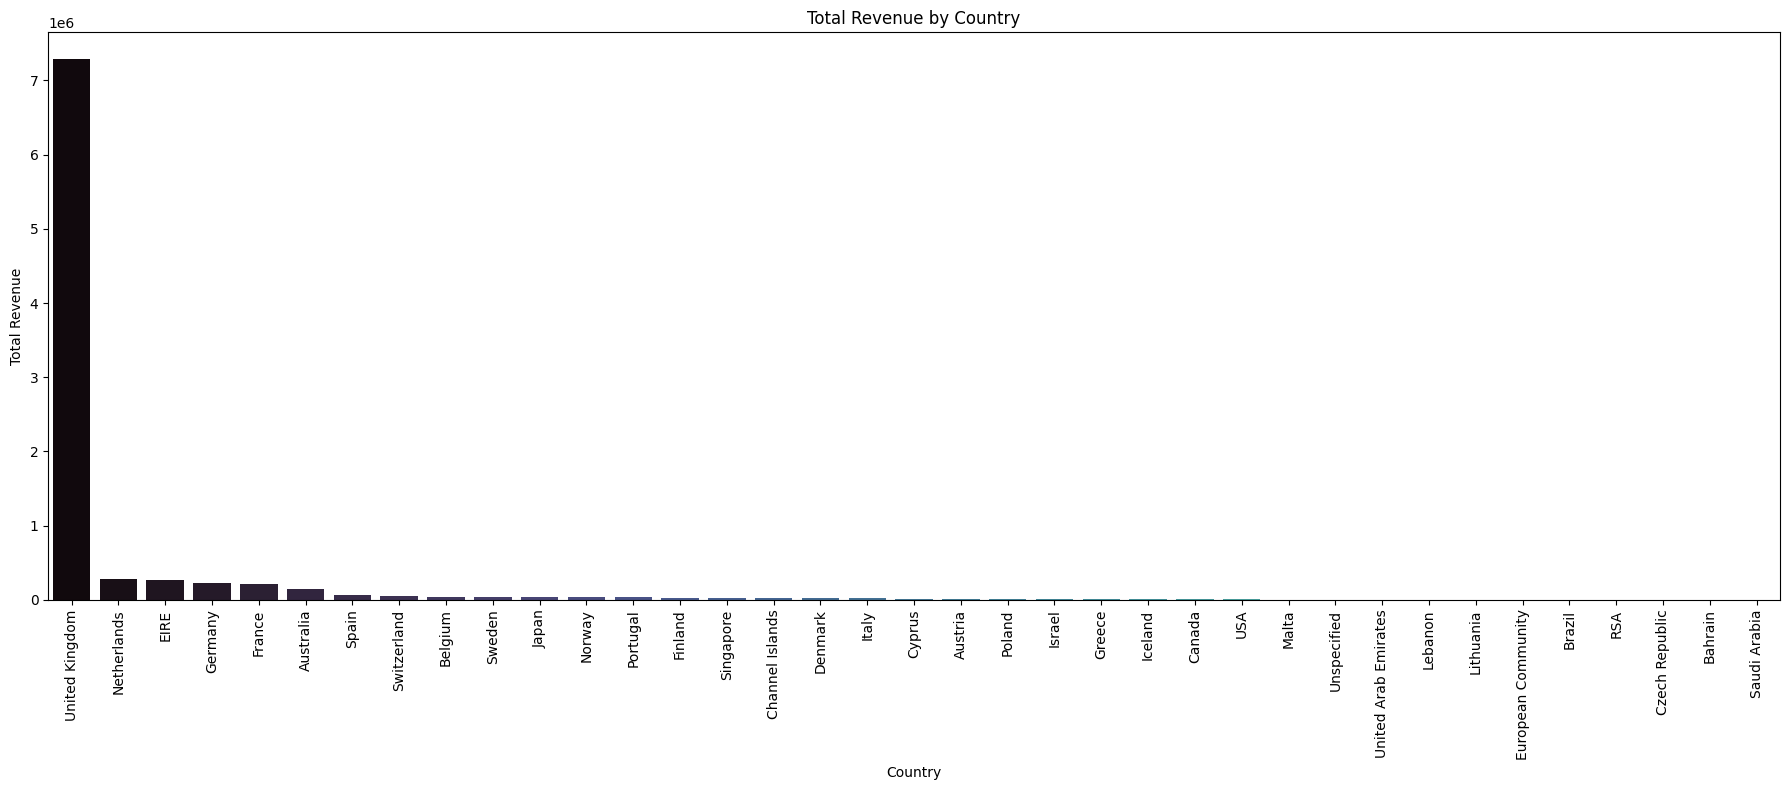

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Group by country and calculate total revenue
revenue_by_country = df.groupby('Country')['TotalRevenue'].sum().sort_values(ascending=False)

# Plot
plt.figure(figsize=(18, 8))
sns.barplot(x=revenue_by_country.index, y=revenue_by_country.values, palette='mako')
plt.title('Total Revenue by Country')
plt.xlabel('Country')
plt.ylabel('Total Revenue')
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()


## 4.2 ) line graph for monthly sales trends

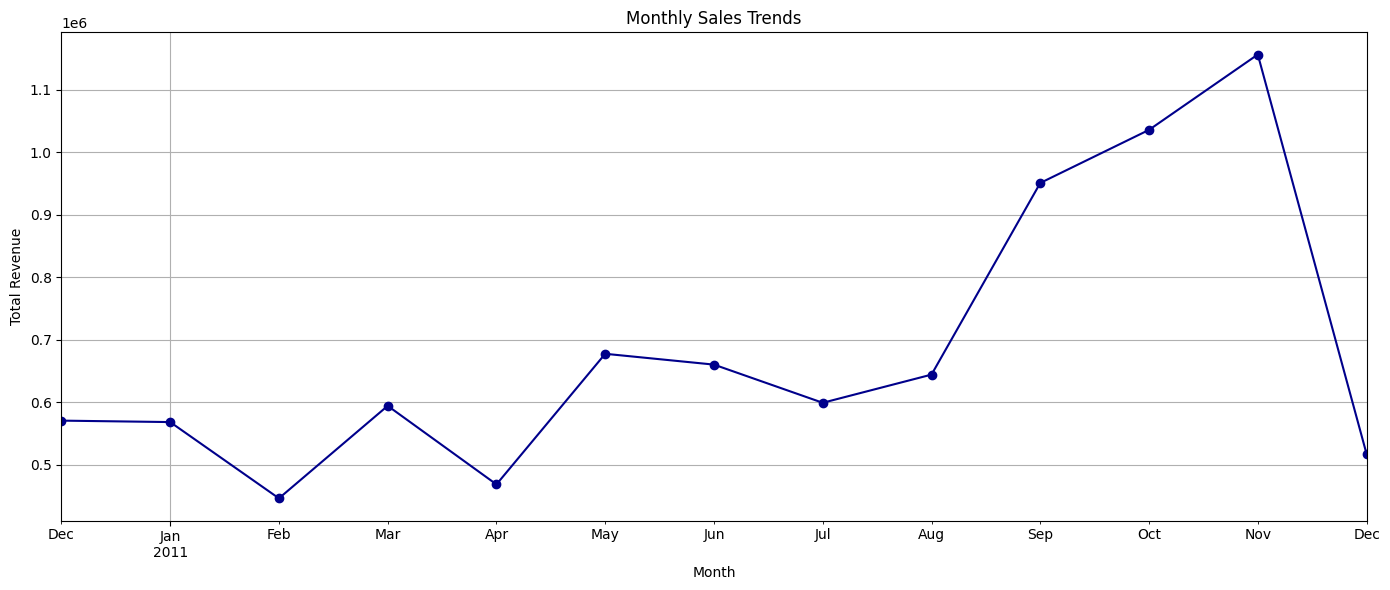

In [ ]:
# Convert InvoiceDate to datetime if not already
df['InvoiceDate'] = pd.to_datetime(df['InvoiceDate'])

# Extract month and year
df['InvoiceMonth'] = df['InvoiceDate'].dt.to_period('M')

# Group by month and sum revenue
monthly_revenue = df.groupby('InvoiceMonth')['TotalRevenue'].sum()

# Plot
plt.figure(figsize=(14, 6))
monthly_revenue.plot(kind='line', marker='o', color='darkblue')
plt.title('Monthly Sales Trends')
plt.xlabel('Month')
plt.ylabel('Total Revenue')
plt.grid(True)
plt.tight_layout()
plt.show()


## 4.3 ) Histogram showing the distribution of order quantities

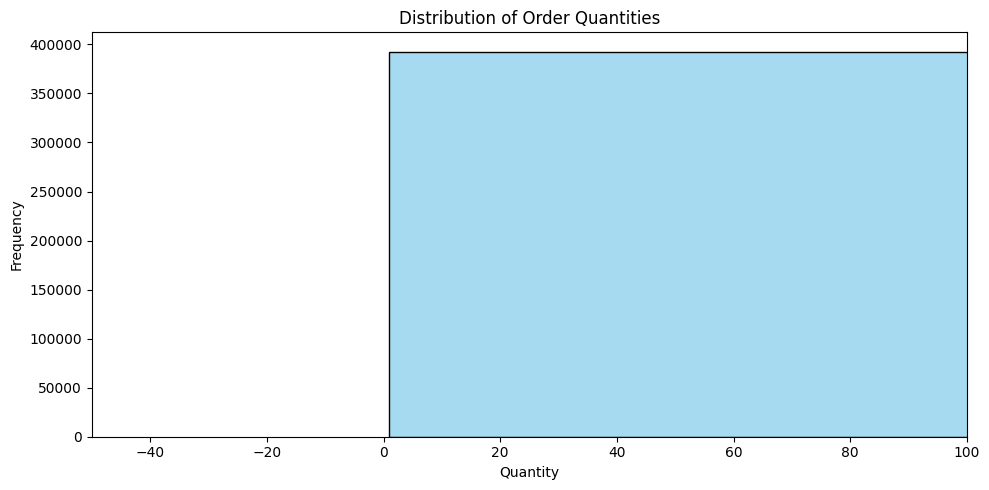

In [ ]:
plt.figure(figsize=(10, 5))
sns.histplot(df['Quantity'], bins=50, kde=False, color='skyblue')
plt.title('Distribution of Order Quantities')
plt.xlabel('Quantity')
plt.ylabel('Frequency')
plt.xlim(-50, 100)  # Trim extreme values for readability
plt.tight_layout()
plt.show()


## 4.4 ) Scatter plot for the relationship between Quantity and TotalRevenue

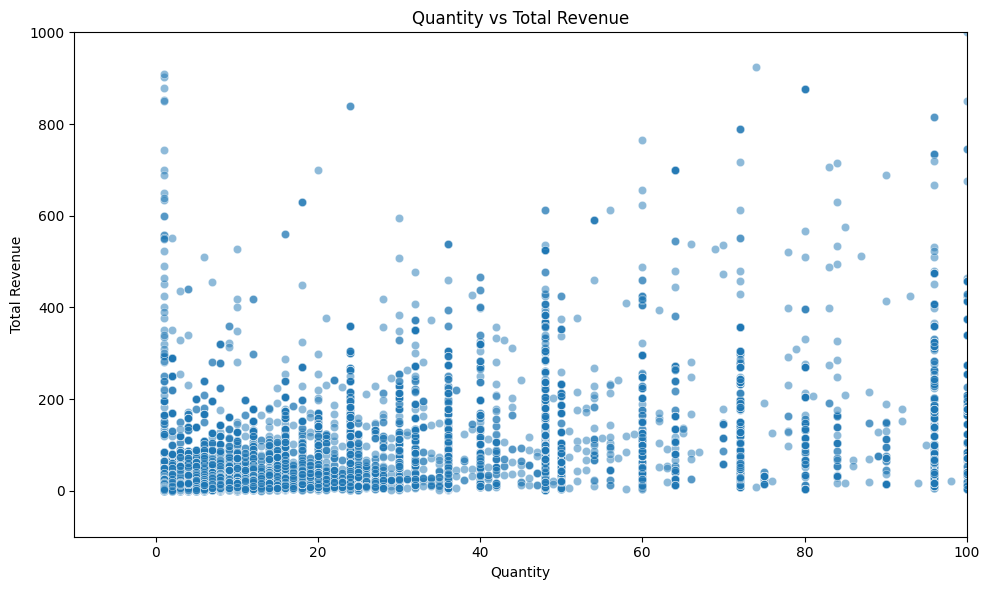

In [ ]:
plt.figure(figsize=(10, 6))
sns.scatterplot(data=df, x='Quantity', y='TotalRevenue', alpha=0.5)
plt.title('Quantity vs Total Revenue')
plt.xlabel('Quantity')
plt.ylabel('Total Revenue')
plt.xlim(-10, 100)
plt.ylim(-100, 1000)
plt.tight_layout()
plt.show()
